In [2]:
!{sys.executable} -m pip install -q openneuro-py openpyxl

/bin/bash: line 1: {sys.executable}: command not found


In [1]:
import os, sys, re, json, time, shutil, subprocess
from pathlib import Path
import numpy as np
import pandas as pd

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"

PROJECT = Path.cwd()                         
ROOT    = PROJECT / "nnunet_fcd"
LOGS    = ROOT / "jobs"
PRED    = ROOT / "predictions"
os.environ["nnUNet_raw"]          = str(ROOT / "nnUNet_raw")
os.environ["nnUNet_preprocessed"] = str(ROOT / "nnUNet_preprocessed")
os.environ["nnUNet_results"]      = str(ROOT / "nnUNet_results")
raw = Path(os.environ["nnUNet_raw"])
BIN = Path(sys.executable).parent

IDEAS       = PROJECT / "ideas"
IDEAS_BIDS  = IDEAS / "bids"
IDEAS_META  = IDEAS / "meta"
IDEAS_MASKS = IDEAS / "masks"
JOBS_FT     = ROOT / "jobs_ft"
for p in [IDEAS_BIDS, IDEAS_META, IDEAS_MASKS, JOBS_FT]:
    p.mkdir(parents=True, exist_ok=True)

DS_FULL, DS_T1 = 501, 502
NAME_FULL, NAME_T1 = "Dataset501_FCD_T1FLAIR", "Dataset502_FCD_T1only"
PLANS, TRAINER, TOTAL_EPOCHS = "nnUNetResEncUNetMPlans", "nnUNetTrainer_FCD", 250

DS_EXT, NAME_EXT = 503, "Dataset503_IDEAS_ext"
DS_MIX, NAME_MIX = 504, "Dataset504_FCD_BonnIDEAS"
FT_TRAINER      = "nnUNetTrainer_FCDft"
TEST_ALL        = ROOT / "test_all"
PRED_BASE_IDEAS = PRED / "IDEAS_by_base"

if (ROOT / "cases.csv").exists():
    df = pd.read_csv(ROOT / "cases.csv")
if (ROOT / "ideas_cases.csv").exists():
    ideas_df = pd.read_csv(ROOT / "ideas_cases.csv")

import signal, datetime as dt
MSK = dt.timezone(dt.timedelta(hours=3))
import nnunetv2
TRAINER_FILE = Path(nnunetv2.__file__).parent / "training" / "nnUNetTrainer" / "nnUNetTrainer_FCD.py"

def _alive(pid):
    try: os.kill(pid, 0); return True
    except ProcessLookupError: return False
    except PermissionError: return True

def run_bg(name, cmd, gpus=None, extra_env=None):
    pid_file = LOGS / f"{name}.pid"
    if pid_file.exists() and _alive(int(pid_file.read_text())):
        print(f"'{name}' уже работает"); return
    env = os.environ.copy()
    if gpus is not None: env["CUDA_VISIBLE_DEVICES"] = gpus
    env.update({k: str(v) for k, v in (extra_env or {}).items()})
    p = subprocess.Popen([str(c) for c in cmd], cwd=PROJECT, env=env,
                         stdout=open(LOGS / f"{name}.log", "a"), stderr=subprocess.STDOUT,
                         stdin=subprocess.DEVNULL, start_new_session=True, preexec_fn=lambda: os.nice(10))
    pid_file.write_text(str(p.pid))
    print(f"Запущено '{name}' (PID {p.pid})")

def tail(path, n=15):
    path = Path(path)
    return "".join(open(path, errors="ignore").readlines()[-n:]) if path.exists() else "(лога нет)"

print("Папка проекта:", PROJECT)
print("Таблицы кладите сюда:", IDEAS_META)
print("Маски кладите сюда:  ", IDEAS_MASKS)
print("\nСейчас в meta: ", [f.name for f in IDEAS_META.iterdir()])
print("Сейчас в masks:", [f.name for f in IDEAS_MASKS.iterdir()])

Папка проекта: /home/lobarevadv/projects/mrt
Таблицы кладите сюда: /home/lobarevadv/projects/mrt/ideas/meta
Маски кладите сюда:   /home/lobarevadv/projects/mrt/ideas/masks

Сейчас в meta:  ['Metadata_Controls_Release.csv', 'Metadata_Release_Anon.csv']
Сейчас в masks: ['masks.zip', '__MACOSX', 'masks']


In [25]:
import zipfile
for z in list(IDEAS_META.rglob("*.zip")) + list(IDEAS_MASKS.rglob("*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(z.parent)
    print("распакован", z.name)

meta_files = [p for p in IDEAS_META.rglob("*") if p.suffix.lower() in (".csv", ".tsv", ".xlsx", ".xls")]
mask_files = sorted(IDEAS_MASKS.rglob("*.nii*"))
print("\nТаблицы:", *meta_files, sep="\n  ")
print(f"\nМасок: {len(mask_files)}. Примеры:")
for m in mask_files[:8]:
    print("  ", m.relative_to(IDEAS_MASKS))

# список субъектов и наличие FLAIR — без скачивания снимков
tree = IDEAS / "tree"
if not tree.exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--no-checkout",
                    "https://github.com/OpenNeuroDatasets/ds005602.git", str(tree)], check=True)
files = subprocess.run(["git", "-C", str(tree), "ls-tree", "-r", "--name-only", "HEAD"],
                       capture_output=True, text=True).stdout.split()
all_subs  = sorted({f.split("/")[0] for f in files if f.startswith("sub-")})
has_flair = {f.split("/")[0] for f in files if f.endswith("_FLAIR.nii.gz")}
print(f"\nСубъектов в OpenNeuro: {len(all_subs)}, с FLAIR: {len(has_flair)}")

распакован masks.zip

Таблицы:
  /home/lobarevadv/projects/mrt/ideas/meta/Metadata_Controls_Release.csv
  /home/lobarevadv/projects/mrt/ideas/meta/Metadata_Release_Anon.csv

Масок: 878. Примеры:
   __MACOSX/masks/sub-1/ses-1/._sub-1_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-10/ses-1/._sub-10_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-100/ses-1/._sub-100_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-102/ses-1/._sub-102_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-103/ses-1/._sub-103_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-104/ses-1/._sub-104_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-105/ses-1/._sub-105_ses-1_space-native_resection.nii.gz
   __MACOSX/masks/sub-106/ses-1/._sub-106_ses-1_space-native_resection.nii.gz

Субъектов в OpenNeuro: 542, с FLAIR: 493


In [26]:
META_FILE = IDEAS_META / "Metadata_Release_Anon.csv"           # если таблиц несколько — выберите нужную по номеру
meta = (pd.read_excel(META_FILE) if META_FILE.suffix.lower() in (".xlsx", ".xls")
        else pd.read_csv(META_FILE, sep=None, engine="python"))
print(META_FILE.name, meta.shape)
print(meta.columns.tolist())
display(meta.head())
for c in meta.columns:
    if any(k in c.lower() for k in ["id", "hist", "path", "ilae", "outcome", "group", "control", "diag"]):
        print(f"\n== {c} ==")
        print(meta[c].value_counts(dropna=False).head(15))

Metadata_Release_Anon.csv (443, 20)
['ID', 'Sex', 'Binned_Onset_Age', 'FUS', 'fqFUS', 'FBTCS', 'fqFBTCS', 'SE', 'Op_Side', 'Op_Type', 'Pathology', 'OP MEMO', 'Number_ASMs', 'Binned_Age_at_Scan', 'Binned_Age_at_Surgery', 'ILAE_Year1', 'ILAE_Year2', 'ILAE_Year3', 'ILAE_Year4', 'ILAE_Year5']


,ID,Sex,Binned_Onset_Age,FUS,fqFUS,FBTCS,fqFBTCS,SE,Op_Side,Op_Type,Pathology,OP MEMO,Number_ASMs,Binned_Age_at_Scan,Binned_Age_at_Surgery,ILAE_Year1,ILAE_Year2,ILAE_Year3,ILAE_Year4,ILAE_Year5
0,1,M,1 to 2,True,2.0,True,3.00,False,R,T Lx,OTHER,oligodendroglial hyperplasia,3,20 to 24,20 to 24,4.0,4.0,4.0,4.0,NaN
1,2,F,15 to 19,True,42.0,True,0.33,False,R,T Lx,HS,type 1,1,35 to 39,35 to 39,1.0,1.0,1.0,1.0,NaN
2,3,M,15 to 19,True,1.5,True,0.00,False,L,T Lesx,DNT,NaN,2,25 to 29,25 to 29,1.0,1.0,1.0,1.0,1.0
3,4,M,11 to 14,True,10.0,False,NaN,False,R,T Lx,OTHER,EFG,2,40 to 44,45 to 49,4.0,4.0,2.0,2.0,2.0
4,5,F,5 to 7,True,4.0,True,0.00,False,L,T Lx,HS,type 1; (& FCD type IIIA),2,45 to 49,45 to 49,2.0,1.0,NaN,NaN,NaN



== ID ==
ID
209    2
1      1
2      1
3      1
4      1
5      1
6      1
7      1
8      1
9      1
10     1
11     1
12     1
13     1
14     1
Name: count, dtype: int64

== Op_Side ==
Op_Side
L    235
R    208
Name: count, dtype: int64

== Pathology ==
Pathology
HS        215
OTHER      74
DNT        52
FCD        40
CAV        33
DUAL       21
GL          5
TREBLE      2
TBC         1
Name: count, dtype: int64

== ILAE_Year1 ==
ILAE_Year1
1.0    246
4.0     64
3.0     53
2.0     47
5.0     18
NaN     15
Name: count, dtype: int64

== ILAE_Year2 ==
ILAE_Year2
1.0    239
4.0     75
3.0     39
NaN     39
2.0     32
5.0     19
Name: count, dtype: int64

== ILAE_Year3 ==
ILAE_Year3
1.0    188
NaN     86
4.0     79
3.0     41
2.0     32
5.0     17
Name: count, dtype: int64

== ILAE_Year4 ==
ILAE_Year4
1.0    169
NaN    131
4.0     66
3.0     32
2.0     23
5.0     21
6.0      1
Name: count, dtype: int64

== ILAE_Year5 ==
ILAE_Year5
NaN    176
1.0    153
4.0     54
3.0     24
5.0     18
2

In [27]:
ID_COL   = "ID"
HIST_COL = "Pathology"
ILAE_COL = "ILAE_Year1"
GOOD_ILAE = ["1"]           # 1 = без приступов через год после операции
FCD_PATTERN = r"fcd|cortical dysplas"

def to_sub(x):
    s = str(x).strip()
    if s.lower().startswith("sub-"):
        return "sub-" + s[4:]
    try:
        return f"sub-{int(float(s))}"
    except ValueError:
        return "sub-" + s

meta["sub"] = meta[ID_COL].map(to_sub)
is_fcd  = meta[HIST_COL].astype(str).str.contains(FCD_PATTERN, case=False, regex=True)
good    = meta[ILAE_COL].astype(str).str.extract(r"(\d)")[0].isin(GOOD_ILAE)
patients = sorted(set(meta.loc[is_fcd & good, "sub"]) & has_flair)
controls = sorted((set(all_subs) - set(meta["sub"])) & has_flair)   # субъекты без клиники = контроли

def find_mask(sub):
    c = [m for m in mask_files
         if not m.name.startswith("._")                 # служебные файлы macOS
         and m.name.startswith(f"{sub}_")                # точно этот субъект
         and "native" in m.name]
    return c[0] if c else None

rows = []
for s in patients:
    m = find_mask(s)
    if m is not None:
        rows.append(dict(sub=s, control=False, mask=str(m)))
rows += [dict(sub=s, control=True, mask=None) for s in controls]
ideas_df = pd.DataFrame(rows)
ideas_df["case_id"] = ["IDEAS_" + s.split("-")[1].zfill(4) for s in ideas_df["sub"]]

rng = np.random.default_rng(42)
ideas_df["part"] = "train"
for ctrl in [False, True]:
    idx = ideas_df[ideas_df.control == ctrl].index.to_numpy()
    ideas_df.loc[rng.choice(idx, len(idx) // 2, replace=False), "part"] = "test"
ideas_df.to_csv(ROOT / "ideas_cases.csv", index=False)

print(f"Пациентов с ФКД + ILAE {GOOD_ILAE} + FLAIR + маска: {(~ideas_df.control).sum()}")
print(f"Контролей с FLAIR: {ideas_df.control.sum()}")
print(ideas_df.groupby(["part", "control"]).size())
print("\nПроверьте, что маски нашлись правильно:")
display(ideas_df[~ideas_df.control].head(5)[["sub", "mask"]])

Пациентов с ФКД + ILAE ['1'] + FLAIR + маска: 16
Контролей с FLAIR: 83
part   control
test   False       8
       True       41
train  False       8
       True       42
dtype: int64

Проверьте, что маски нашлись правильно:


,sub,mask
0,sub-110,/home/lobarevadv/projects/mrt/ideas/masks/mask...
1,sub-116,/home/lobarevadv/projects/mrt/ideas/masks/mask...
2,sub-138,/home/lobarevadv/projects/mrt/ideas/masks/mask...
3,sub-166,/home/lobarevadv/projects/mrt/ideas/masks/mask...
4,sub-172,/home/lobarevadv/projects/mrt/ideas/masks/mask...


In [28]:
import openneuro
include = [f"{s}/anat/*" for s in ideas_df["sub"]]
openneuro.download(dataset="ds005602", target_dir=str(IDEAS_BIDS), include=include)
print("Скачано субъектов:", len(list(IDEAS_BIDS.glob("sub-*"))))

🌍 Preparing to download ds005602 …
📥 Checking 399 files, downloading as needed (5 concurrent downloads). 


/home/lobarevadv/projects/mrt/.venv/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

✅ Finished downloading ds005602 (downloaded 0 files and 0 B).
Скачано субъектов: 99


In [29]:
import SimpleITK as sitk
from joblib import Parallel, delayed

def register_rigid(fixed, moving):
    f, m = sitk.Cast(fixed, sitk.sitkFloat32), sitk.Cast(moving, sitk.sitkFloat32)
    init = sitk.CenteredTransformInitializer(f, m, sitk.Euler3DTransform(),
                                             sitk.CenteredTransformInitializerFilter.GEOMETRY)
    R = sitk.ImageRegistrationMethod()
    R.SetMetricAsMattesMutualInformation(50)
    R.SetMetricSamplingStrategy(R.RANDOM); R.SetMetricSamplingPercentage(0.1, seed=42)
    R.SetInterpolator(sitk.sitkLinear)
    R.SetOptimizerAsRegularStepGradientDescent(2.0, 1e-4, 200)
    R.SetOptimizerScalesFromPhysicalShift()
    R.SetShrinkFactorsPerLevel([4, 2, 1]); R.SetSmoothingSigmasPerLevel([2, 1, 0])
    R.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()
    R.SetInitialTransform(init, inPlace=False)
    return R.Execute(f, m)

ext_img, ext_lab = raw / NAME_EXT / "imagesTs", raw / NAME_EXT / "labelsTs"
ext_img.mkdir(parents=True, exist_ok=True); ext_lab.mkdir(parents=True, exist_ok=True)

def convert_ideas(r):
    lab_path = ext_lab / f"{r.case_id}.nii.gz"
    if lab_path.exists():
        return r.case_id, "skip"
    try:
        anat = IDEAS_BIDS / r.sub / "anat"
        t1 = sitk.ReadImage(str(anat / f"{r.sub}_T1w.nii.gz"), sitk.sitkFloat32)
        fl = sitk.ReadImage(str(anat / f"{r.sub}_FLAIR.nii.gz"), sitk.sitkFloat32)
        fl_r = sitk.Resample(fl, t1, register_rigid(t1, fl), sitk.sitkLinear, 0.0, sitk.sitkFloat32)
        if r.control:
            lab = sitk.Image(t1.GetSize(), sitk.sitkUInt8); lab.CopyInformation(t1)
        else:
            m = sitk.ReadImage(r.mask)
            if m.GetSize() == t1.GetSize():
                m.CopyInformation(t1); lab = m
            else:
                lab = sitk.Resample(m, t1, sitk.Transform(), sitk.sitkNearestNeighbor, 0)
            lab = sitk.Cast(lab > 0, sitk.sitkUInt8)
        sitk.WriteImage(t1, str(ext_img / f"{r.case_id}_0000.nii.gz"))
        sitk.WriteImage(fl_r, str(ext_img / f"{r.case_id}_0001.nii.gz"))
        sitk.WriteImage(lab, str(lab_path))
        return r.case_id, int(sitk.GetArrayFromImage(lab).sum())
    except Exception as e:
        return r.case_id, f"ERROR: {e}"

res = Parallel(n_jobs=12, verbose=5)(delayed(convert_ideas)(r) for r in ideas_df.itertuples())
errs = [x for x in res if isinstance(x[1], str) and x[1].startswith("ERROR")]
empty = [cid for cid, v in res if v == 0 and not ideas_df.set_index("case_id").loc[cid, "control"]]
print("Ошибок:", len(errs), *errs[:5], sep="\n")
print("Пациентов с пустой маской резекции:", empty)
bad = {e[0] for e in errs} | set(empty)
ideas_df = ideas_df[~ideas_df.case_id.isin(bad)].reset_index(drop=True)
ideas_df.to_csv(ROOT / "ideas_cases.csv", index=False)
print("Готово, случаев:", len(ideas_df))

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:   10.5s
[Parallel(n_jobs=12)]: Done  96 out of  99 | elapsed:   13.3s remaining:    0.4s


Ошибок:
0
Пациентов с пустой маской резекции: []
Готово, случаев: 99


[Parallel(n_jobs=12)]: Done  99 out of  99 | elapsed:   15.4s finished


In [32]:
!nvidia-smi --query-gpu=index,memory.used,utilization.gpu,temperature.gpu --format=csv
FREE_GPU = "0"     # <-- поставьте карту, на которой занято меньше ~1 ГБ (только "0" или "1")
run_bg("pred_ideas_base", [BIN / "nnUNetv2_predict", "-i", raw / NAME_EXT / "imagesTs", "-o", PRED_BASE_IDEAS,
                           "-d", DS_FULL, "-c", "3d_fullres", "-p", PLANS, "-tr", TRAINER, "-f", "0",
                           "--save_probabilities", "-npp", "2", "-nps", "2", "--continue_prediction"],
       gpus=FREE_GPU)

index, memory.used [MiB], utilization.gpu [%], temperature.gpu
0, 2747 MiB, 100 %, 82
1, 0 MiB, 0 %, 57
2, 0 MiB, 0 %, 56
'pred_ideas_base' уже работает


In [36]:
n_done = len(list(PRED_BASE_IDEAS.glob("*.nii.gz"))) if PRED_BASE_IDEAS.exists() else 0
print(f"Готово {n_done} из {len(ideas_df)}")
print(tail(LOGS / "pred_ideas_base.log", 3))

Готово 99 из 99
Segmentation export complete.



In [14]:
%%writefile {LOGS}/thermal2.py
import os, sys, time, json, signal, subprocess, fcntl
from pathlib import Path

JOBS = Path(__file__).resolve().parent
PAUSE, RESUME, MAX_PAUSE_MIN = 85, 78, 30

lock = open(JOBS / "thermal2.lock", "w")
try:
    fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
except BlockingIOError:
    sys.exit(0)

frozen = {}


def log(*a):
    print(time.strftime("[%Y-%m-%d %H:%M:%S]"), *a, flush=True)


def cont(pg):
    try:
        os.killpg(pg, signal.SIGCONT)
    except ProcessLookupError:
        pass


def release_all(*_):
    for pg in list(frozen):
        cont(pg)
    log("сторож остановлен, все паузы сняты")
    sys.exit(0)


for s in (signal.SIGTERM, signal.SIGINT, signal.SIGHUP):
    signal.signal(s, release_all)


def temps():
    out = subprocess.run(["nvidia-smi", "-i", "0,1", "--query-gpu=index,temperature.gpu",
                          "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return {int(a): int(b) for a, b in (l.split(",") for l in out.strip().splitlines())}


def groups():
    res = {}
    pids = subprocess.run(["pgrep", "-u", str(os.getuid()), "-f", "nnUNetv2_(train|predict)"],
                          capture_output=True, text=True).stdout.split()
    for pid in pids:
        try:
            env = open(f"/proc/{pid}/environ", "rb").read().split(b"\0")
            gpu = next((e.split(b"=", 1)[1].decode() for e in env if e.startswith(b"CUDA_VISIBLE_DEVICES=")), None)
            if gpu in ("0", "1"):
                res[os.getpgid(int(pid))] = int(gpu)
        except Exception:
            pass
    return res


log(f"сторож запущен: пауза при {PAUSE}°C, продолжение при {RESUME}°C")
while not (JOBS / "thermal2.stop").exists():
    try:
        t, g = temps(), groups()
        for pg, gpu in g.items():
            tg = t.get(gpu)
            if tg is None:
                continue
            if pg not in frozen and tg >= PAUSE:
                os.killpg(pg, signal.SIGSTOP); frozen[pg] = (gpu, time.time())
                log(f"карта {gpu}: {tg}°C — ПАУЗА")
            elif pg in frozen and (tg <= RESUME or (time.time() - frozen[pg][1]) / 60 > MAX_PAUSE_MIN):
                cont(pg); frozen.pop(pg)
                log(f"карта {gpu}: {tg}°C — продолжено")
        for pg in list(frozen):
            if pg not in g:
                frozen.pop(pg)
        (JOBS / "thermal2.json").write_text(json.dumps(
            {"ts": time.time(), "temps": t, "paused": sorted(v[0] for v in frozen.values())}))
    except Exception as e:
        log("ошибка:", e)
    time.sleep(20)
release_all()

Writing /home/lobarevadv/projects/mrt/nnunet_fcd/jobs/thermal2.py


In [15]:
(LOGS / "thermal2.stop").unlink(missing_ok=True)
run_bg("thermal2", [sys.executable, "-u", LOGS / "thermal2.py"])
time.sleep(25)
print(tail(LOGS / "thermal2.log", 5))

Запущено 'thermal2' (PID 3305731)
[2026-11-04 14:51:34] сторож запущен: пауза при 85°C, продолжение при 78°C
[2026-11-04 14:51:34] карта 0: 91°C — ПАУЗА
[2026-11-04 14:51:54] карта 0: 76°C — продолжено



In [6]:
from scipy import ndimage
import SimpleITK as sitk
MIN_VOX = 20

def clusters(pr):
    lab, n = ndimage.label(pr)
    sizes = ndimage.sum(pr, lab, range(1, n + 1))
    return lab, [i + 1 for i, s in enumerate(sizes) if s >= MIN_VOX]

def eval_bonn(pred_dir):
    det, fp_p, clean, fp_c = [], [], [], []
    for r in df[df.split == "test"].itertuples():
        gt = sitk.GetArrayFromImage(sitk.ReadImage(str(raw / NAME_FULL / "labelsTs" / f"{r.case_id}.nii.gz"))) > 0
        pr = sitk.GetArrayFromImage(sitk.ReadImage(str(Path(pred_dir) / f"{r.case_id}.nii.gz"))) > 0
        lab, keep = clusters(pr)
        hits = sum(gt[lab == i].any() for i in keep)
        if r.control: clean.append(len(keep) == 0); fp_c.append(len(keep))
        else:         det.append(hits > 0); fp_p.append(len(keep) - hits)
    return {"Бонн: чувств.": f"{np.mean(det):.2f} ({sum(det)}/{len(det)})",
            "Бонн: ложн./пац.": round(np.mean(fp_p), 2),
            "Бонн: специф.": f"{np.mean(clean):.2f}"}

def eval_ideas(pred_dir, cases):
    det, fp_p, clean = [], [], []
    for r in cases.itertuples():
        rz = sitk.GetArrayFromImage(sitk.ReadImage(str(raw / NAME_EXT / "labelsTs" / f"{r.case_id}.nii.gz"))) > 0
        pr = sitk.GetArrayFromImage(sitk.ReadImage(str(Path(pred_dir) / f"{r.case_id}.nii.gz"))) > 0
        lab, keep = clusters(pr)
        hits = sum(rz[lab == i].any() for i in keep)
        if r.control: clean.append(len(keep) == 0)
        else:         det.append(hits > 0); fp_p.append(len(keep) - hits)
    return {"IDEAS: в зоне резекции": f"{np.mean(det):.2f} ({sum(det)}/{len(det)})",
            "IDEAS: ложн./пац.": round(np.mean(fp_p), 2),
            "IDEAS: специф.": f"{np.mean(clean):.2f} ({sum(clean)}/{len(clean)})"}

ideas_df = pd.read_csv(ROOT / "ideas_cases.csv")
print("Исходная модель на ВСЕХ отобранных IDEAS:")
display(pd.DataFrame([eval_ideas(PRED_BASE_IDEAS, ideas_df)]))

Исходная модель на ВСЕХ отобранных IDEAS:


,IDEAS: в зоне резекции,IDEAS: ложн./пац.,IDEAS: специф.
0,0.44 (7/16),1.38,0.45 (37/83)


In [38]:
from nnunetv2.dataset_conversion.generate_dataset_json import generate_dataset_json

PSEUDO_THR = 0.3
mix = raw / NAME_MIX
(mix / "imagesTr").mkdir(parents=True, exist_ok=True); (mix / "labelsTr").mkdir(parents=True, exist_ok=True)

def link(src, dst):
    if not dst.exists(): os.symlink(src, dst)

# Бонн (обучающая часть) — как есть
for cid in df[df.split == "train"].case_id:
    for ch in ["0000", "0001"]:
        link(raw / NAME_FULL / "imagesTr" / f"{cid}_{ch}.nii.gz", mix / "imagesTr" / f"{cid}_{ch}.nii.gz")
    link(raw / NAME_FULL / "labelsTr" / f"{cid}.nii.gz", mix / "labelsTr" / f"{cid}.nii.gz")

# IDEAS (обучающая половина)
n_pseudo = 0
for r in ideas_df[ideas_df.part == "train"].itertuples():
    for ch in ["0000", "0001"]:
        link(raw / NAME_EXT / "imagesTs" / f"{r.case_id}_{ch}.nii.gz", mix / "imagesTr" / f"{r.case_id}_{ch}.nii.gz")
    out = mix / "labelsTr" / f"{r.case_id}.nii.gz"
    if out.exists(): continue
    rz_img = sitk.ReadImage(str(raw / NAME_EXT / "labelsTs" / f"{r.case_id}.nii.gz"))
    rz = sitk.GetArrayFromImage(rz_img) > 0
    lab = np.zeros(rz.shape, np.uint8)
    if not r.control:
        lab[rz] = 2
        prob = np.load(PRED_BASE_IDEAS / f"{r.case_id}.npz")["probabilities"][1]
        pseudo = (prob >= PSEUDO_THR) & rz
        lab[pseudo] = 1
        n_pseudo += pseudo.any()
    o = sitk.GetImageFromArray(lab); o.CopyInformation(rz_img)
    sitk.WriteImage(o, str(out))

n_tr = len(list((mix / "labelsTr").glob("*.nii.gz")))
generate_dataset_json(str(mix), {0: "T1", 1: "FLAIR"}, {"background": 0, "FCD": 1, "ignore": 2},
                      n_tr, ".nii.gz", dataset_name=NAME_MIX, license="CC0 / CC BY 4.0")

# общий тест: Бонн-тест + IDEAS-тест
TEST_ALL.mkdir(exist_ok=True)
for f in (raw / NAME_FULL / "imagesTs").glob("*.nii.gz"):
    link(f, TEST_ALL / f.name)
for cid in ideas_df[ideas_df.part == "test"].case_id:
    for ch in ["0000", "0001"]:
        link(raw / NAME_EXT / "imagesTs" / f"{cid}_{ch}.nii.gz", TEST_ALL / f"{cid}_{ch}.nii.gz")

print(f"Обучающих случаев Бонн+IDEAS: {n_tr} | пациентов IDEAS с псевдоразметкой: {n_pseudo}")
print("Тестовых случаев всего:", len(list(TEST_ALL.glob('*_0000.nii.gz'))))

Обучающих случаев Бонн+IDEAS: 190 | пациентов IDEAS с псевдоразметкой: 3
Тестовых случаев всего: 79


In [40]:
(Path(os.environ["nnUNet_preprocessed"]) / NAME_MIX).mkdir(parents=True, exist_ok=True)
!CUDA_VISIBLE_DEVICES="" {BIN}/nnUNetv2_move_plans_between_datasets -s {DS_FULL} -t {DS_MIX} -sp {PLANS} -tp {PLANS}
print((Path(os.environ["nnUNet_preprocessed"]) / NAME_MIX / f"{PLANS}.json").exists())   # должно быть True

True


In [41]:
%%writefile {TRAINER_FILE.parent / "nnUNetTrainer_FCDft.py"}
from nnunetv2.training.nnUNetTrainer.nnUNetTrainer import nnUNetTrainer


class nnUNetTrainer_FCDft(nnUNetTrainer):
    def initialize(self):
        self.num_epochs = 100
        self.initial_lr = 1e-3
        self.oversample_foreground_percent = 1.0
        self.save_every = 10
        super().initialize()

Writing /home/lobarevadv/projects/mrt/.venv/lib/python3.12/site-packages/nnunetv2/training/nnUNetTrainer/nnUNetTrainer_FCDft.py


In [42]:
!{sys.executable} -c "from nnunetv2.training.nnUNetTrainer.nnUNetTrainer_FCDft import nnUNetTrainer_FCDft; print('Тренер OK')"

Тренер OK


In [43]:
   (LOGS / "thermal2.stop").touch()
   time.sleep(30)
   print(tail(LOGS / "thermal2.log", 2))

[2026-11-04 15:23:30] карта 0: 71°C — продолжено
[2026-11-04 15:28:16] сторож остановлен, все паузы сняты



In [44]:
%%writefile {JOBS_FT}/supervisor.py
import os, sys, json, time, signal, shutil, subprocess, fcntl, threading
from pathlib import Path

JOBS = Path(__file__).resolve().parent
CFG = json.loads((JOBS / "config.json").read_text())
for k in ["nnUNet_raw", "nnUNet_preprocessed", "nnUNet_results"]:
    os.environ[k] = CFG[k]
RES = Path(CFG["nnUNet_results"])
BIN = str(Path(CFG["PY"]).parent)
STOP, DONE, FAILED, STATUS = JOBS / "STOP", JOBS / "ALL_DONE", JOBS / "FAILED", JOBS / "status.json"
MODELS = CFG["MODELS"]

TEMP_PAUSE, TEMP_RESUME = 85, 78
RAM_PAUSE, RAM_RESUME, DISK_STOP = 8, 20, 10
STALL_MIN, MAX_RESTARTS, PRE_STALL_MIN = 45, 6, 20
FREE_MIB = 1500


def now():
    return time.strftime("%Y-%m-%d %H:%M:%S")


def log(*a):
    print(f"[{now()}]", *a, flush=True)


if STOP.exists() or DONE.exists() or FAILED.exists():
    sys.exit(0)
_lock = open(JOBS / "supervisor.lock", "w")
try:
    fcntl.flock(_lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
except BlockingIOError:
    sys.exit(0)

quit_ev = threading.Event()
state = {"stage": "start", "models": {}, "guard": {}}
st_lock, pr_lock = threading.Lock(), threading.Lock()
procs = {}


def save_status(**kw):
    with st_lock:
        state.update(kw)
        state["heartbeat_ts"] = time.time()
        tmp = STATUS.with_suffix(".tmp")
        tmp.write_text(json.dumps(state, ensure_ascii=False, indent=1))
        os.replace(tmp, STATUS)


def set_model(tag, **kw):
    with st_lock:
        state["models"].setdefault(tag, {}).update(kw, time=now())
    save_status()


def should_stop():
    return STOP.exists() or quit_ev.is_set()


def make_env(gpu):
    env = os.environ.copy()
    env["PATH"] = BIN + ":" + env.get("PATH", "/usr/local/bin:/usr/bin:/bin")
    env["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
    env["CUDA_VISIBLE_DEVICES"] = "" if gpu is None else str(gpu)
    env["nnUNet_n_proc_DA"] = str(CFG["N_DA"])
    return env


def start(cmd, env, logfile):
    lf = open(logfile, "a")
    lf.write(f"\n===== {now()} : {' '.join(map(str, cmd))}\n"); lf.flush()
    return subprocess.Popen([str(c) for c in cmd], env=env, stdout=lf, stderr=subprocess.STDOUT,
                            stdin=subprocess.DEVNULL, start_new_session=True)


def sig(p, s):
    try:
        os.killpg(p.pid, s)
    except ProcessLookupError:
        pass


def terminate(p, timeout=900):
    if p.poll() is not None:
        return
    sig(p, signal.SIGCONT); sig(p, signal.SIGTERM)
    try:
        p.wait(timeout=timeout)
    except subprocess.TimeoutExpired:
        sig(p, signal.SIGKILL); p.wait()


def tail(path, n=3000):
    try:
        with open(path, "rb") as f:
            f.seek(0, 2); f.seek(max(0, f.tell() - n))
            return f.read().decode(errors="ignore")
    except Exception:
        return ""


def has_ckpt(d, kind):
    return any(d.glob(f"checkpoint_{kind}.*"))


def gpu_used_mib(gpu):
    try:
        out = subprocess.run(["nvidia-smi", "-i", str(gpu), "--query-gpu=memory.used",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
        return int(out.strip().splitlines()[0])
    except Exception:
        return 0


def guard():
    while not quit_ev.is_set():
        temps = {}
        try:
            out = subprocess.run(["nvidia-smi", "-i", "0,1", "--query-gpu=index,temperature.gpu",
                                  "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
            for line in out.strip().splitlines():
                i, t = [x.strip() for x in line.split(",")]
                temps[int(i)] = int(t)
        except Exception:
            pass
        ram = 999.0
        try:
            for line in open("/proc/meminfo"):
                if line.startswith("MemAvailable"):
                    ram = int(line.split()[1]) / 1e6
        except Exception:
            pass
        disk = shutil.disk_usage(RES).free / 1e9
        if disk < DISK_STOP and not STOP.exists():
            STOP.write_text(f"Остановлено автоматически: на диске {disk:.0f} ГБ")
        paused = {}
        with pr_lock:
            for tag, info in procs.items():
                r, t = info["reasons"], temps.get(info["gpu"])
                if t is not None and t >= TEMP_PAUSE: r.add("перегрев")
                if t is not None and t <= TEMP_RESUME: r.discard("перегрев")
                if ram < RAM_PAUSE: r.add("мало RAM")
                if ram > RAM_RESUME: r.discard("мало RAM")
                p = info["p"]
                if p.poll() is None:
                    if r and not info["frozen"]:
                        sig(p, signal.SIGSTOP); info["frozen"] = True; log(f"[{tag}] ПАУЗА: {r}")
                    elif not r and info["frozen"]:
                        sig(p, signal.SIGCONT); info["frozen"] = False; info["resumed_at"] = time.time()
                        log(f"[{tag}] продолжено")
                if info["frozen"]:
                    paused[tag] = sorted(r)
        save_status(guard={"temp_C": temps, "ram_free_GB": round(ram, 1),
                           "disk_free_GB": round(disk, 1), "paused": paused})
        time.sleep(30)


def run_step(cmd, logname):
    logf = JOBS / logname
    p = start(cmd, make_env(None), logf)
    t0 = time.time()
    while p.poll() is None:
        time.sleep(30)
        if should_stop():
            terminate(p, 60); return "stop"
        if (time.time() - max(logf.stat().st_mtime, t0)) / 60 > PRE_STALL_MIN:
            terminate(p, 30); return "hang"
    return p.returncode


def preprocess():
    marker = JOBS / "preprocess.done"
    if marker.exists() or not CFG["PREPROCESS_DS"]:
        return True
    for attempt, npr in enumerate([4, 2, 1], start=1):
        if should_stop():
            return False
        save_status(stage="preprocessing", attempt=attempt)
        log("препроцессинг, процессов", npr)
        rc = run_step(["nnUNetv2_preprocess", "-d", *map(str, CFG["PREPROCESS_DS"]),
                       "-plans_name", CFG["PLANS"], "-c", "3d_fullres", "-np", str(npr)], "preprocess.log")
        if rc == 0:
            marker.touch(); log("препроцессинг готов"); return True
        if rc == "stop":
            return False
        log("препроцессинг: ошибка/зависание", rc)
    FAILED.write_text("Препроцессинг не прошёл:\n" + tail(JOBS / "preprocess.log", 2000))
    return False


def model_job(m):
    tag, ds, name, gpu, trainer = m["tag"], m["ds"], m["name"], m["gpu"], m["trainer"]
    assert gpu in (0, 1)
    fold = RES / name / f"{trainer}__{CFG['PLANS']}__3d_fullres" / "fold_0"
    tlog, env, restarts = JOBS / f"train_{tag}.log", make_env(gpu), 0

    while not has_ckpt(fold, "final"):
        if should_stop():
            set_model(tag, state="остановлено"); return
        subprocess.run(["pkill", "-f", f"nnUNetv2_train {ds} 3d_fullres 0 -p {CFG['PLANS']} -tr {trainer}"])
        time.sleep(5)
        while gpu_used_mib(gpu) > FREE_MIB and not should_stop():
            set_model(tag, state=f"жду свободную карту {gpu} (занято {gpu_used_mib(gpu)} МиБ)")
            time.sleep(60)
        if should_stop():
            continue
        extra = ["--c"] if has_ckpt(fold, "latest") else (["-pretrained_weights", m["pretrained"]] if m.get("pretrained") else [])
        set_model(tag, state="training", gpu=gpu, restarts=restarts)
        log(f"[{tag}] обучение на карте {gpu}", extra[:1])
        p = start(["nnUNetv2_train", str(ds), "3d_fullres", "0", "-p", CFG["PLANS"], "-tr", trainer, "--npz"] + extra,
                  env, tlog)
        info = {"p": p, "gpu": gpu, "reasons": set(), "frozen": False, "resumed_at": time.time()}
        with pr_lock:
            procs[tag] = info
        while p.poll() is None:
            time.sleep(30)
            if should_stop():
                set_model(tag, state="останавливаю"); terminate(p); set_model(tag, state="остановлено")
                with pr_lock: procs.pop(tag, None)
                return
            if info["frozen"]:
                continue
            logs = list(fold.glob("training_log_*.txt"))
            if (time.time() - max([f.stat().st_mtime for f in logs] + [info["resumed_at"]])) / 60 > STALL_MIN:
                log(f"[{tag}] завис — перезапуск"); terminate(p, 120); break
        with pr_lock:
            procs.pop(tag, None)
        if has_ckpt(fold, "final"):
            break
        if "out of memory" in tail(tlog).lower():
            set_model(tag, state="FAILED_OOM", error=tail(tlog, 1500)); return
        restarts += 1
        if restarts > MAX_RESTARTS:
            set_model(tag, state="FAILED", error=tail(tlog, 1500)); return
        set_model(tag, state="упало — перезапуск через 2 мин", restarts=restarts, error=tail(tlog, 800))
        time.sleep(120)

    pin, pout = Path(m["test_in"]), Path(m["pred_out"])
    n_in = len(list(pin.glob("*_0000.nii.gz")))
    for attempt in range(3):
        if pout.exists() and len(list(pout.glob("*.nii.gz"))) >= n_in:
            break
        if should_stop():
            return
        set_model(tag, state="predicting")
        p = start(["nnUNetv2_predict", "-i", pin, "-o", pout, "-d", str(ds), "-c", "3d_fullres",
                   "-p", CFG["PLANS"], "-tr", trainer, "-f", "0", "--save_probabilities",
                   "-npp", "2", "-nps", "2", "--continue_prediction"], env, JOBS / f"predict_{tag}.log")
        while p.poll() is None:
            time.sleep(30)
            if should_stop():
                terminate(p, 60); return
    ok = pout.exists() and len(list(pout.glob("*.nii.gz"))) >= n_in
    set_model(tag, state="DONE" if ok else "FAILED_predict")


def on_signal(*_):
    log("сигнал от системы — завершаюсь, cron перезапустит")
    quit_ev.set()


for s in (signal.SIGTERM, signal.SIGINT, signal.SIGHUP):
    signal.signal(s, on_signal)

log("супервизор дообучения запущен, PID", os.getpid())
threading.Thread(target=guard, daemon=True).start()
if preprocess():
    save_status(stage="training")
    threads = [threading.Thread(target=model_job, args=(m,)) for m in MODELS]
    for t in threads: t.start()
    for t in threads: t.join()
    states = [state["models"].get(m["tag"], {}).get("state", "") for m in MODELS]
    if all(s == "DONE" for s in states):
        DONE.touch(); save_status(stage="ALL_DONE"); log("ВСЁ ГОТОВО")
    elif any(s.startswith("FAILED") for s in states):
        FAILED.write_text(f"Ошибка: {states}"); save_status(stage="FAILED")
quit_ev.set()

Writing /home/lobarevadv/projects/mrt/nnunet_fcd/jobs_ft/supervisor.py


In [45]:
base_fold = Path(os.environ["nnUNet_results"]) / NAME_FULL / f"{TRAINER}__{PLANS}__3d_fullres" / "fold_0"
base_ckpt = str(next(base_fold.glob("checkpoint_final.*")))
cfg_ft = {"PY": sys.executable, "PLANS": PLANS, "N_DA": max(2, (os.cpu_count() or 8) // 2 - 4),
          "nnUNet_raw": os.environ["nnUNet_raw"], "nnUNet_preprocessed": os.environ["nnUNet_preprocessed"],
          "nnUNet_results": os.environ["nnUNet_results"],
          "PREPROCESS_DS": [DS_MIX],
          "MODELS": [
              {"tag": "bonn_ideas", "ds": DS_MIX, "name": NAME_MIX, "gpu": 0, "trainer": FT_TRAINER,
               "pretrained": base_ckpt, "test_in": str(TEST_ALL), "pred_out": str(PRED / "FT_BonnIDEAS")},
              {"tag": "bonn_only", "ds": DS_FULL, "name": NAME_FULL, "gpu": 1, "trainer": FT_TRAINER,
               "pretrained": base_ckpt, "test_in": str(TEST_ALL), "pred_out": str(PRED / "FT_BonnOnly")}]}
(JOBS_FT / "config.json").write_text(json.dumps(cfg_ft, indent=1, ensure_ascii=False))

cron_line = (f"*/10 * * * * nice -n 10 {sys.executable} -u {JOBS_FT / 'supervisor.py'} "
             f">> {JOBS_FT / 'supervisor.log'} 2>&1  # FCD_FT")
cur = subprocess.run(["crontab", "-l"], capture_output=True, text=True)
lines = [l for l in cur.stdout.splitlines() if "FCD_FT" not in l] if cur.returncode == 0 else []
subprocess.run(["crontab", "-"], input="\n".join(lines + [cron_line]) + "\n", text=True, check=True)

for f in ["STOP", "FAILED"]:
    (JOBS_FT / f).unlink(missing_ok=True)
p = subprocess.Popen([sys.executable, "-u", str(JOBS_FT / "supervisor.py")], cwd=PROJECT,
                     stdout=open(JOBS_FT / "supervisor.log", "a"), stderr=subprocess.STDOUT,
                     stdin=subprocess.DEVNULL, start_new_session=True, preexec_fn=lambda: os.nice(10))
print("Дообучение запущено, PID", p.pid, "| исходные веса:", Path(base_ckpt).name)

Дообучение запущено, PID 3410346 | исходные веса: checkpoint_final.pth


In [3]:
import shutil
src = raw / NAME_MIX / "dataset.json"
dst = Path(os.environ["nnUNet_preprocessed"]) / NAME_MIX / "dataset.json"
shutil.copy(src, dst)
print("dataset.json скопирован:", dst.exists())

for f in ["FAILED", "STOP", "preprocess.done"]:
    (JOBS_FT / f).unlink(missing_ok=True)

p = subprocess.Popen([sys.executable, "-u", str(JOBS_FT / "supervisor.py")], cwd=PROJECT,
                     stdout=open(JOBS_FT / "supervisor.log", "a"), stderr=subprocess.STDOUT,
                     stdin=subprocess.DEVNULL, start_new_session=True, preexec_fn=lambda: os.nice(10))
print("Дообучение перезапущено, PID", p.pid)

dataset.json скопирован: True
Дообучение перезапущено, PID 3416361


In [5]:
!CUDA_VISIBLE_DEVICES="" {BIN}/nnUNetv2_extract_fingerprint -d {DS_MIX} -np 4 2>&1 | tail -3
print("fingerprint есть:", (Path(os.environ["nnUNet_preprocessed"]) / NAME_MIX / "dataset_fingerprint.json").exists())

Dataset504_FCD_BonnIDEAS
Using <class 'nnunetv2.imageio.simpleitk_reader_writer.SimpleITKIO'> as reader/writer
Extracting dataset fingerprint: 100%|██████████| 190/190 [00:49<00:00,  3.86it/s]
fingerprint есть: True


In [6]:
(JOBS_FT / "STOP").write_text("перезапуск после исправления")
for _ in range(60):
    time.sleep(10)
    st = json.loads((JOBS_FT / "status.json").read_text())
    if time.time() - st.get("heartbeat_ts", 0) > 90:
        print("Остановлен"); break
else:
    print("ещё останавливается — подождите пару минут и запустите шаг 3")

Остановлен


In [7]:
for f in ["STOP", "FAILED", "ALL_DONE"]:
    (JOBS_FT / f).unlink(missing_ok=True)
p = subprocess.Popen([sys.executable, "-u", str(JOBS_FT / "supervisor.py")], cwd=PROJECT,
                     stdout=open(JOBS_FT / "supervisor.log", "a"), stderr=subprocess.STDOUT,
                     stdin=subprocess.DEVNULL, start_new_session=True, preexec_fn=lambda: os.nice(10))
print("Перезапущено, PID", p.pid)

Перезапущено, PID 3453197


Сейчас: 05.11 09:53 МСК
✅ ВСЁ ГОТОВО — запускайте ячейку I15
Карты: {'0': 84, '1': 35} °C | RAM: 125.7 ГБ | диск: 123.6 ГБ | пауза: нет

=== Бонн+IDEAS (карта 0) === DONE | перезапусков: 0
Эпоха 100/100 ████████████████████
закончит ~05.11 09:53 МСК


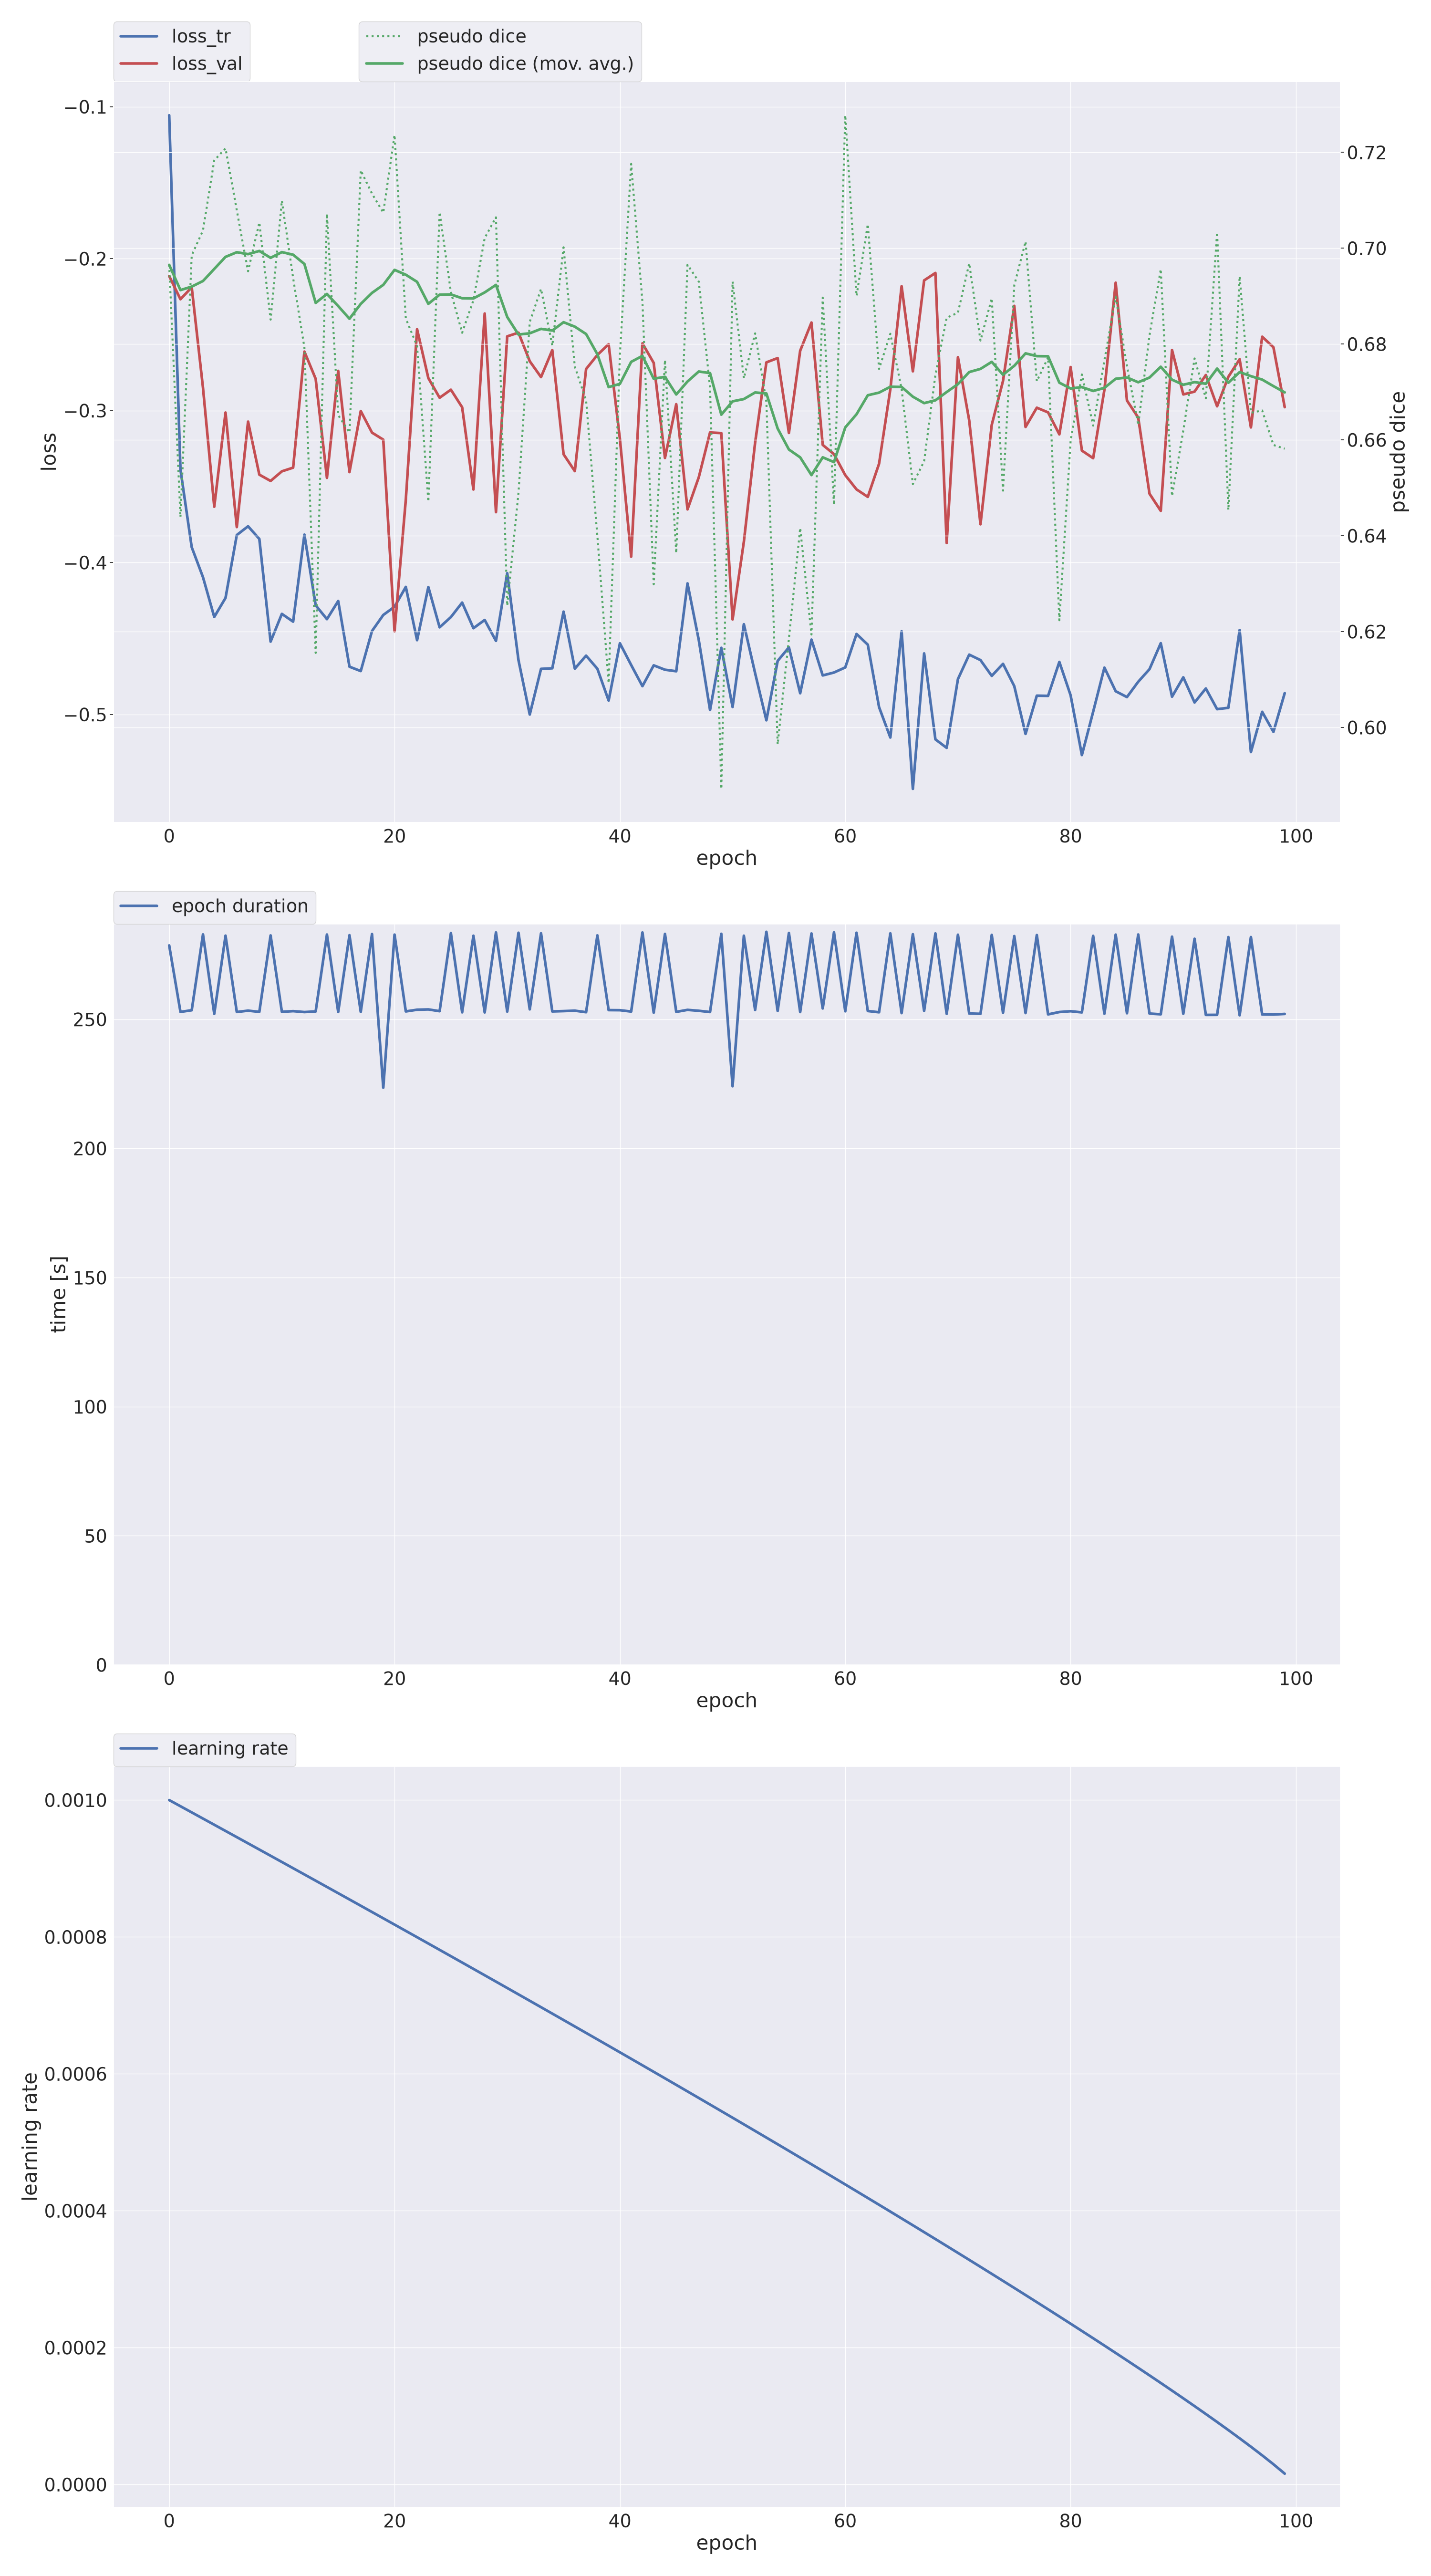


=== только Бонн (карта 1) === DONE | перезапусков: 0
Эпоха 100/100 ████████████████████
закончит ~05.11 09:53 МСК


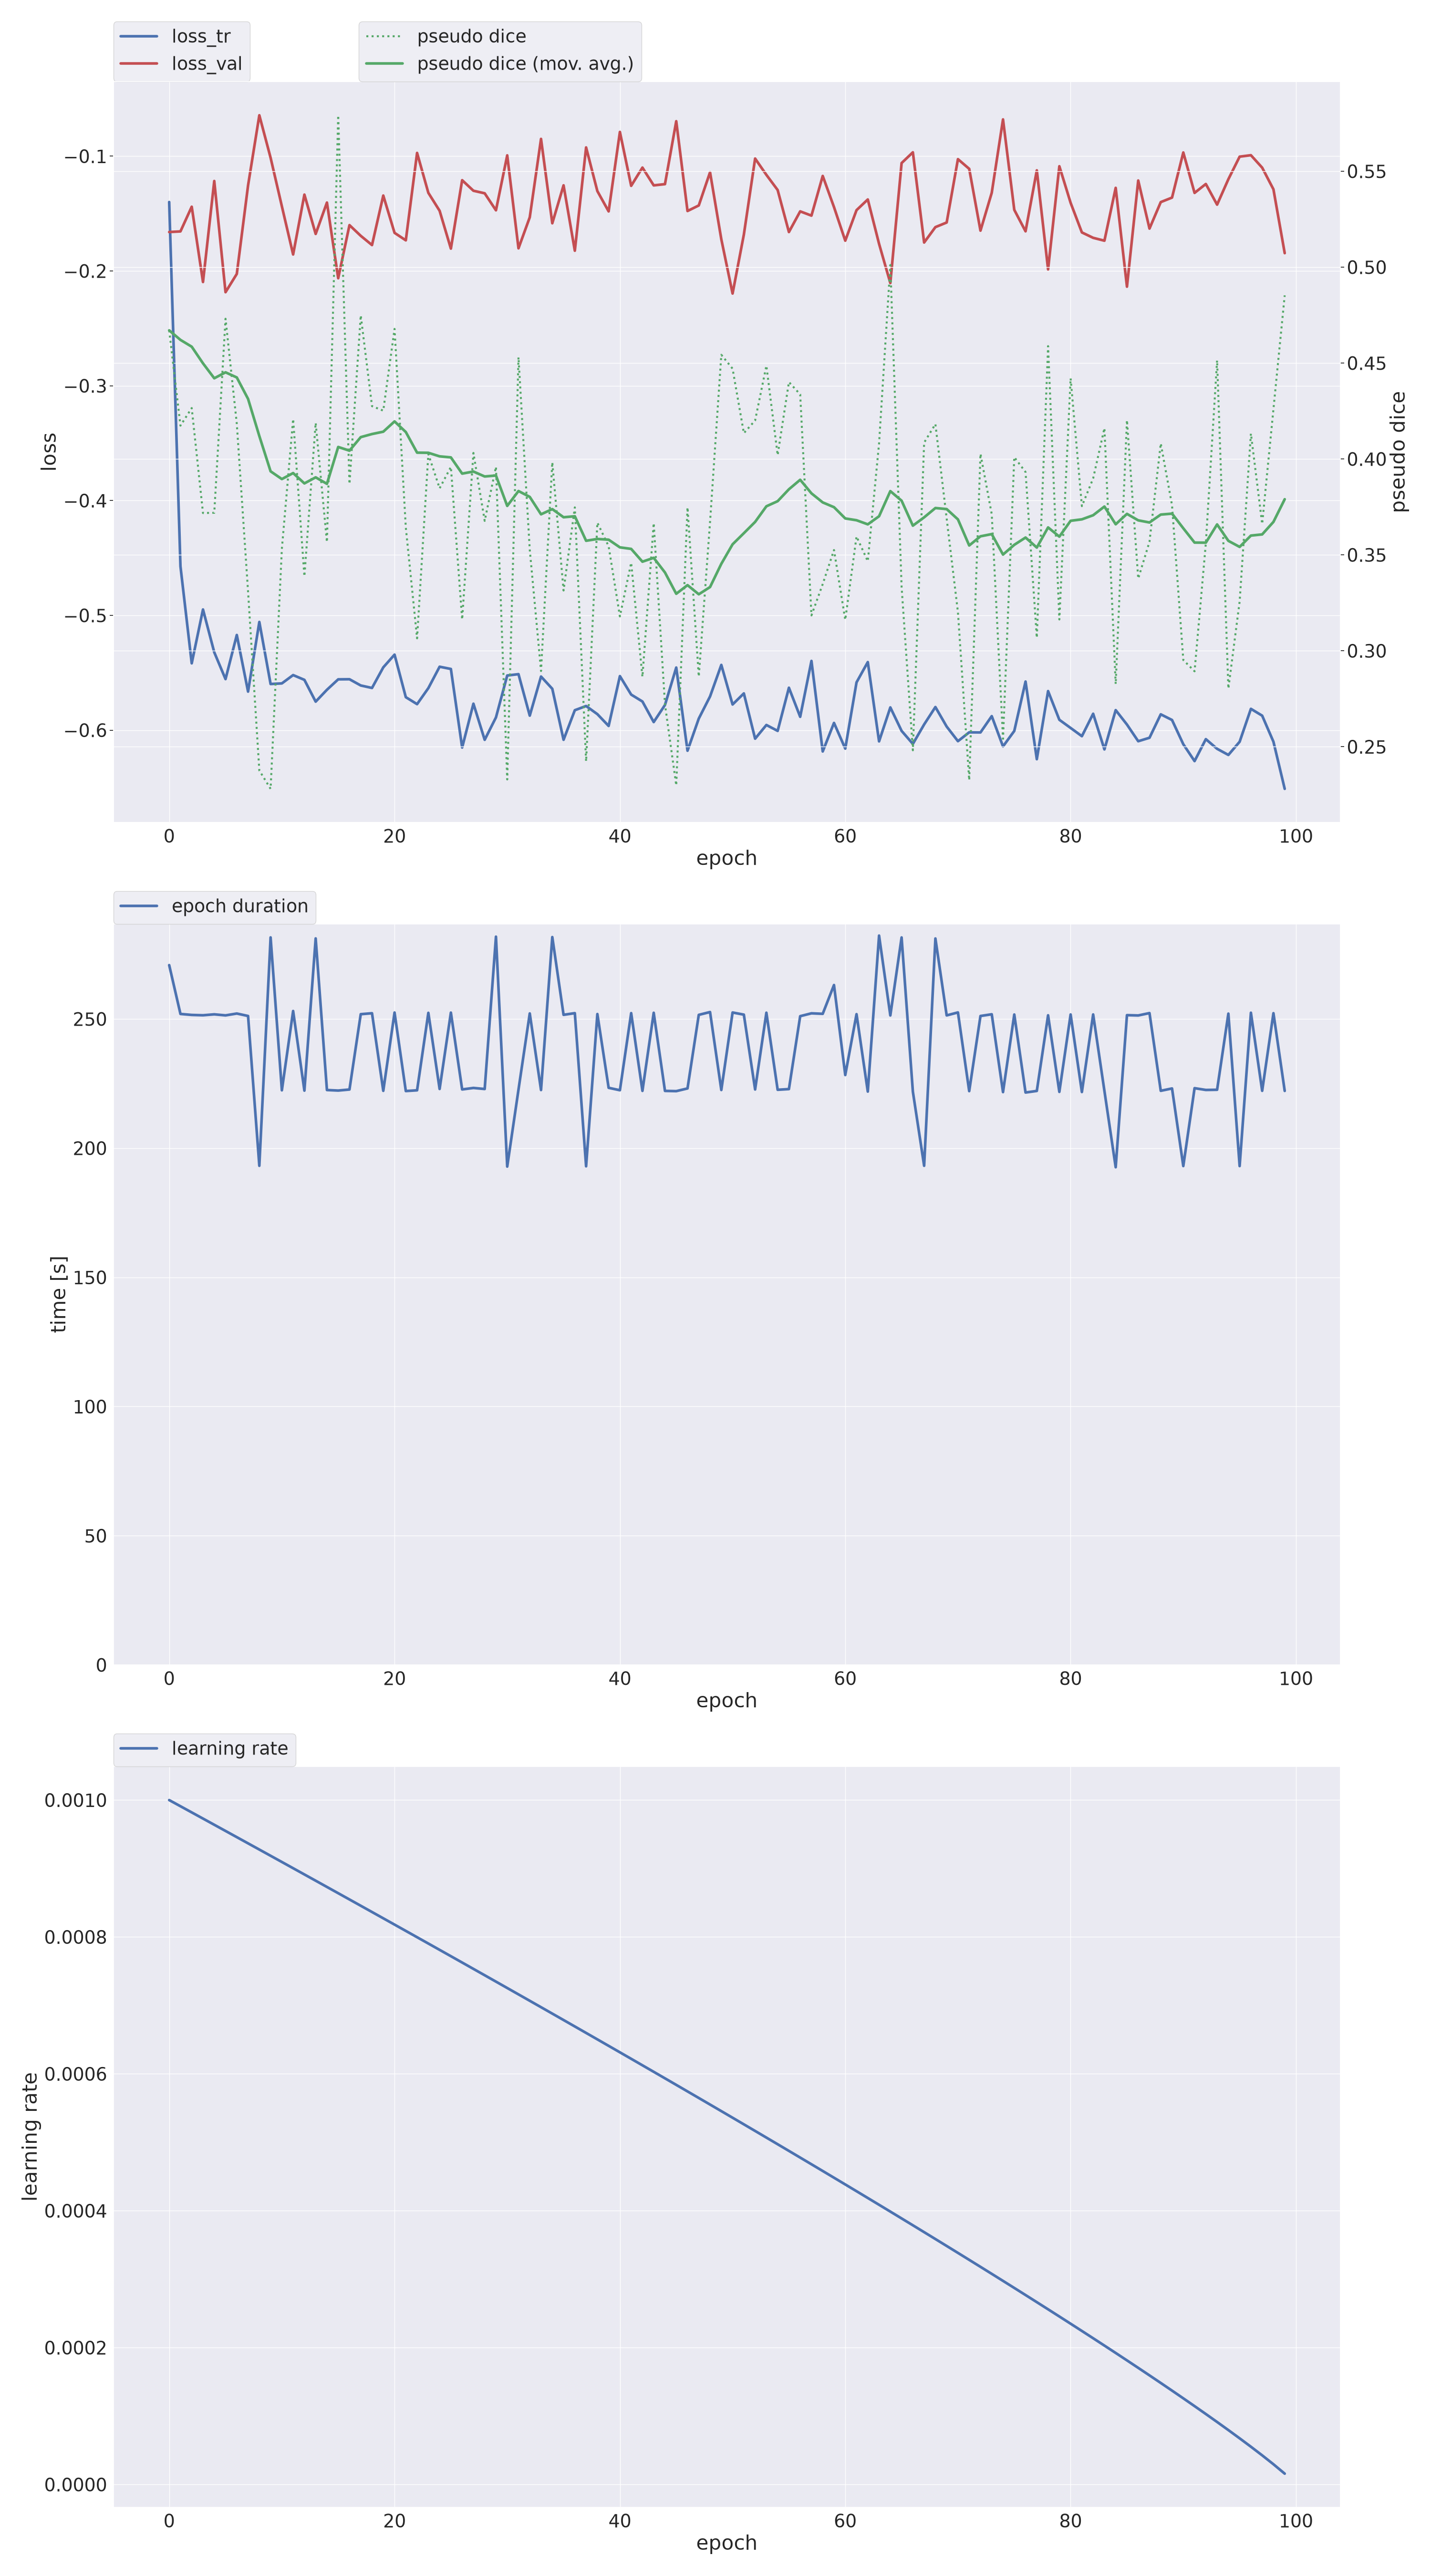


--- журнал ---
[2026-11-05 01:30:44] [bonn_ideas] продолжено
[2026-11-05 01:31:14] [bonn_ideas] ПАУЗА: {'перегрев'}
[2026-11-05 01:31:44] [bonn_ideas] продолжено
[2026-11-05 01:32:14] [bonn_ideas] ПАУЗА: {'перегрев'}
[2026-11-05 01:32:44] [bonn_ideas] продолжено
[2026-11-05 01:56:51] ВСЁ ГОТОВО



In [3]:
from IPython.display import Image, display
FT_EPOCHS = 100
st = json.loads((JOBS_FT / "status.json").read_text()) if (JOBS_FT / "status.json").exists() else {}
age = (time.time() - st.get("heartbeat_ts", 0)) / 60
print("Сейчас:", dt.datetime.now(MSK).strftime("%d.%m %H:%M"), "МСК")
if (JOBS_FT / "ALL_DONE").exists():  print("✅ ВСЁ ГОТОВО — запускайте ячейку I15")
elif (JOBS_FT / "FAILED").exists():  print("❌ ОШИБКА — пришлите вывод\n", (JOBS_FT / "FAILED").read_text()[-1500:])
elif (JOBS_FT / "STOP").exists():    print("⏸ ОСТАНОВЛЕНО:", (JOBS_FT / "STOP").read_text())
elif age < 3:                        print(f"🟢 РАБОТАЕТ | этап: {st.get('stage')}")
else:                                print(f"🔴 Не отвечает {age:.0f} мин — cron перезапустит")
g = st.get("guard", {})
if g: print(f"Карты: {g.get('temp_C')} °C | RAM: {g.get('ram_free_GB')} ГБ | диск: {g.get('disk_free_GB')} ГБ | пауза: {g.get('paused') or 'нет'}")

for tag, name, title in [("bonn_ideas", NAME_MIX, "Бонн+IDEAS (карта 0)"), ("bonn_only", NAME_FULL, "только Бонн (карта 1)")]:
    m = st.get("models", {}).get(tag, {})
    print(f"\n=== {title} === {m.get('state', 'ожидание')} | перезапусков: {m.get('restarts', 0)}")
    if m.get("state", "").startswith(("FAILED", "упало")): print(m.get("error", "")[-600:])
    fold = Path(os.environ["nnUNet_results"]) / name / f"{FT_TRAINER}__{PLANS}__3d_fullres" / "fold_0"
    logs = sorted(fold.glob("training_log_*.txt"))
    if not logs: continue
    text = "\n".join(l.read_text(errors="ignore") for l in logs)
    ep = [int(x) for x in re.findall(r"Epoch (\d+)\s*$", text, flags=re.M)]
    tm = [float(x) for x in re.findall(r"Epoch time: ([\d.]+) s", text)]
    cur = max(ep) + 1 if ep else 0
    print(f"Эпоха {cur}/{FT_EPOCHS} " + "█" * int(cur / FT_EPOCHS * 20) + "░" * (20 - int(cur / FT_EPOCHS * 20)))
    if tm:
        left = (FT_EPOCHS - cur) * np.mean(tm[-10:])
        print(f"закончит ~{(dt.datetime.now(MSK) + dt.timedelta(seconds=left)):%d.%m %H:%M} МСК")
    if (fold / "progress.png").exists(): display(Image(str(fold / "progress.png"), width=550))
print("\n--- журнал ---\n" + tail(JOBS_FT / "supervisor.log", 6))

In [7]:
ideas_test = ideas_df[ideas_df.part == "test"]
rows = []
for title, p_bonn, p_ideas in [("Исходная (250 эп.)",        PRED / NAME_FULL,        PRED_BASE_IDEAS),
                               ("Дообучение: только Бонн",    PRED / "FT_BonnOnly",    PRED / "FT_BonnOnly"),
                               ("Дообучение: Бонн + IDEAS",   PRED / "FT_BonnIDEAS",   PRED / "FT_BonnIDEAS")]:
    r = {"Модель": title}
    r.update(eval_bonn(p_bonn))
    r.update(eval_ideas(p_ideas, ideas_test))
    rows.append(r)
display(pd.DataFrame(rows).set_index("Модель"))

,Бонн: чувств.,Бонн: ложн./пац.,Бонн: специф.,IDEAS: в зоне резекции,IDEAS: ложн./пац.,IDEAS: специф.
Модель,,,,,,
Исходная (250 эп.),0.33 (5/15),0.33,0.93,0.50 (4/8),1.62,0.46 (19/41)
Дообучение: только Бонн,0.33 (5/15),0.40,0.80,0.38 (3/8),2.25,0.37 (15/41)
Дообучение: Бонн + IDEAS,0.33 (5/15),0.40,0.87,0.38 (3/8),0.12,0.90 (37/41)


In [8]:
cur = subprocess.run(["crontab", "-l"], capture_output=True, text=True).stdout
subprocess.run(["crontab", "-"], input="\n".join(l for l in cur.splitlines() if "FCD_" not in l) + "\n", text=True)

CompletedProcess(args=['crontab', '-'], returncode=0)

In [2]:
DS_OVF, NAME_OVF = 505, "Dataset505_FCD_overfit10"
JOBS_OVF = ROOT / "jobs_ovf"; JOBS_OVF.mkdir(parents=True, exist_ok=True)
OVF_TRAINER = "nnUNetTrainer_Overfit"
PRED_OVF = PRED / "overfit10"

rng = np.random.default_rng(0)
pool = df[(df.split == "train") & (~df.control)].case_id.tolist()
ovf_ids = sorted(rng.choice(pool, 10, replace=False).tolist())
print("Выбраны 10 пациентов:", ovf_ids)

ovf = raw / NAME_OVF
for sub in ["imagesTr", "labelsTr", "imagesTs", "labelsTs"]:
    (ovf / sub).mkdir(parents=True, exist_ok=True)
for cid in ovf_ids:
    for ch in ["0000", "0001"]:
        src = raw / NAME_FULL / "imagesTr" / f"{cid}_{ch}.nii.gz"
        for sub in ["imagesTr", "imagesTs"]:                      # тест = трейн
            dst = ovf / sub / src.name
            if not dst.exists(): os.symlink(src, dst)
    src = raw / NAME_FULL / "labelsTr" / f"{cid}.nii.gz"
    for sub in ["labelsTr", "labelsTs"]:
        dst = ovf / sub / src.name
        if not dst.exists(): os.symlink(src, dst)

from nnunetv2.dataset_conversion.generate_dataset_json import generate_dataset_json
generate_dataset_json(str(ovf), {0: "T1", 1: "FLAIR"}, {"background": 0, "FCD": 1},
                      10, ".nii.gz", dataset_name=NAME_OVF, license="CC0")
(ROOT / "overfit10_cases.txt").write_text("\n".join(ovf_ids))
print("Готово: imagesTr =", len(list((ovf / "imagesTr").glob("*.nii.gz"))), "файлов (должно быть 20)")

Выбраны 10 пациентов: ['FCD_002', 'FCD_003', 'FCD_009', 'FCD_032', 'FCD_046', 'FCD_052', 'FCD_071', 'FCD_082', 'FCD_107', 'FCD_124']
Готово: imagesTr = 20 файлов (должно быть 20)


In [3]:
pp_ovf = Path(os.environ["nnUNet_preprocessed"]) / NAME_OVF
pp_ovf.mkdir(parents=True, exist_ok=True)
!CUDA_VISIBLE_DEVICES="" {BIN}/nnUNetv2_extract_fingerprint -d {DS_OVF} -np 2 2>&1 | tail -2
!CUDA_VISIBLE_DEVICES="" {BIN}/nnUNetv2_move_plans_between_datasets -s {DS_FULL} -t {DS_OVF} -sp {PLANS} -tp {PLANS}
shutil.copy(ovf / "dataset.json", pp_ovf / "dataset.json")
for f in ["dataset.json", "dataset_fingerprint.json", f"{PLANS}.json"]:
    print(f, (pp_ovf / f).exists())          # все три должны быть True

Using <class 'nnunetv2.imageio.simpleitk_reader_writer.SimpleITKIO'> as reader/writer
Extracting dataset fingerprint: 100%|██████████| 10/10 [00:11<00:00,  1.18s/it]
dataset.json True
dataset_fingerprint.json True
nnUNetResEncUNetMPlans.json True


In [4]:
%%writefile {TRAINER_FILE.parent / "nnUNetTrainer_Overfit.py"}
from nnunetv2.training.nnUNetTrainer.variants.data_augmentation.nnUNetTrainerNoDA import nnUNetTrainerNoDA


class nnUNetTrainer_Overfit(nnUNetTrainerNoDA):
    def initialize(self):
        self.num_epochs = 100
        self.oversample_foreground_percent = 1.0
        self.save_every = 10
        super().initialize()

Writing /home/lobarevadv/projects/mrt/.venv/lib/python3.12/site-packages/nnunetv2/training/nnUNetTrainer/nnUNetTrainer_Overfit.py


In [5]:
!{sys.executable} -c "from nnunetv2.training.nnUNetTrainer.nnUNetTrainer_Overfit import nnUNetTrainer_Overfit; print('Тренер OK')"

Тренер OK


In [6]:
code = (JOBS_FT / "supervisor.py").read_text()
patches = [
    ('/ "fold_0"',                    "/ f\"fold_{m.get('fold', '0')}\""),
    ("3d_fullres 0 -p",               "3d_fullres {m.get('fold', '0')} -p"),
    ('"3d_fullres", "0", "-p"',       '"3d_fullres", m.get("fold", "0"), "-p"'),
    ('"-f", "0",',                    '"-f", m.get("fold", "0"),'),
]
for old, new in patches:
    assert code.count(old) == 1, f"не найдено: {old}"
    code = code.replace(old, new)
(JOBS_OVF / "supervisor.py").write_text(code)

cfg = {"PY": sys.executable, "PLANS": PLANS, "N_DA": max(2, (os.cpu_count() or 8) // 2 - 4),
       "nnUNet_raw": os.environ["nnUNet_raw"], "nnUNet_preprocessed": os.environ["nnUNet_preprocessed"],
       "nnUNet_results": os.environ["nnUNet_results"], "PREPROCESS_DS": [DS_OVF],
       "MODELS": [{"tag": "overfit10", "ds": DS_OVF, "name": NAME_OVF, "gpu": 0, "fold": "all",
                   "trainer": OVF_TRAINER, "test_in": str(ovf / "imagesTs"), "pred_out": str(PRED_OVF)}]}
(JOBS_OVF / "config.json").write_text(json.dumps(cfg, indent=1, ensure_ascii=False))

cron_line = (f"*/10 * * * * nice -n 10 {sys.executable} -u {JOBS_OVF / 'supervisor.py'} "
             f">> {JOBS_OVF / 'supervisor.log'} 2>&1  # FCD_OVF")
cur = subprocess.run(["crontab", "-l"], capture_output=True, text=True)
lines = [l for l in cur.stdout.splitlines() if "FCD_OVF" not in l] if cur.returncode == 0 else []
subprocess.run(["crontab", "-"], input="\n".join(lines + [cron_line]) + "\n", text=True, check=True)

for f in ["STOP", "FAILED", "ALL_DONE"]:
    (JOBS_OVF / f).unlink(missing_ok=True)
p = subprocess.Popen([sys.executable, "-u", str(JOBS_OVF / "supervisor.py")], cwd=PROJECT,
                     stdout=open(JOBS_OVF / "supervisor.log", "a"), stderr=subprocess.STDOUT,
                     stdin=subprocess.DEVNULL, start_new_session=True, preexec_fn=lambda: os.nice(10))
print("Проверка запущена, PID", p.pid, "| карта 0 (если занята — подождёт)")

Проверка запущена, PID 3690521 | карта 0 (если занята — подождёт)


In [2]:
DS_OVF, NAME_OVF = 505, "Dataset505_FCD_overfit10"
JOBS_OVF    = ROOT / "jobs_ovf"
OVF_TRAINER = "nnUNetTrainer_Overfit"
PRED_OVF    = PRED / "overfit10"
ovf         = raw / NAME_OVF
ovf_ids     = (ROOT / "overfit10_cases.txt").read_text().split()
print("Переменные проверки загружены:", len(ovf_ids), "случаев")

Переменные проверки загружены: 10 случаев


✅ ГОТОВО — запускайте O6
Модель: DONE | перезапусков: 0
Карты: {'0': 70, '1': 42} °C | пауза: нет
Эпоха 100/100 | pseudo Dice на тех же 10 случаях: 0.9906


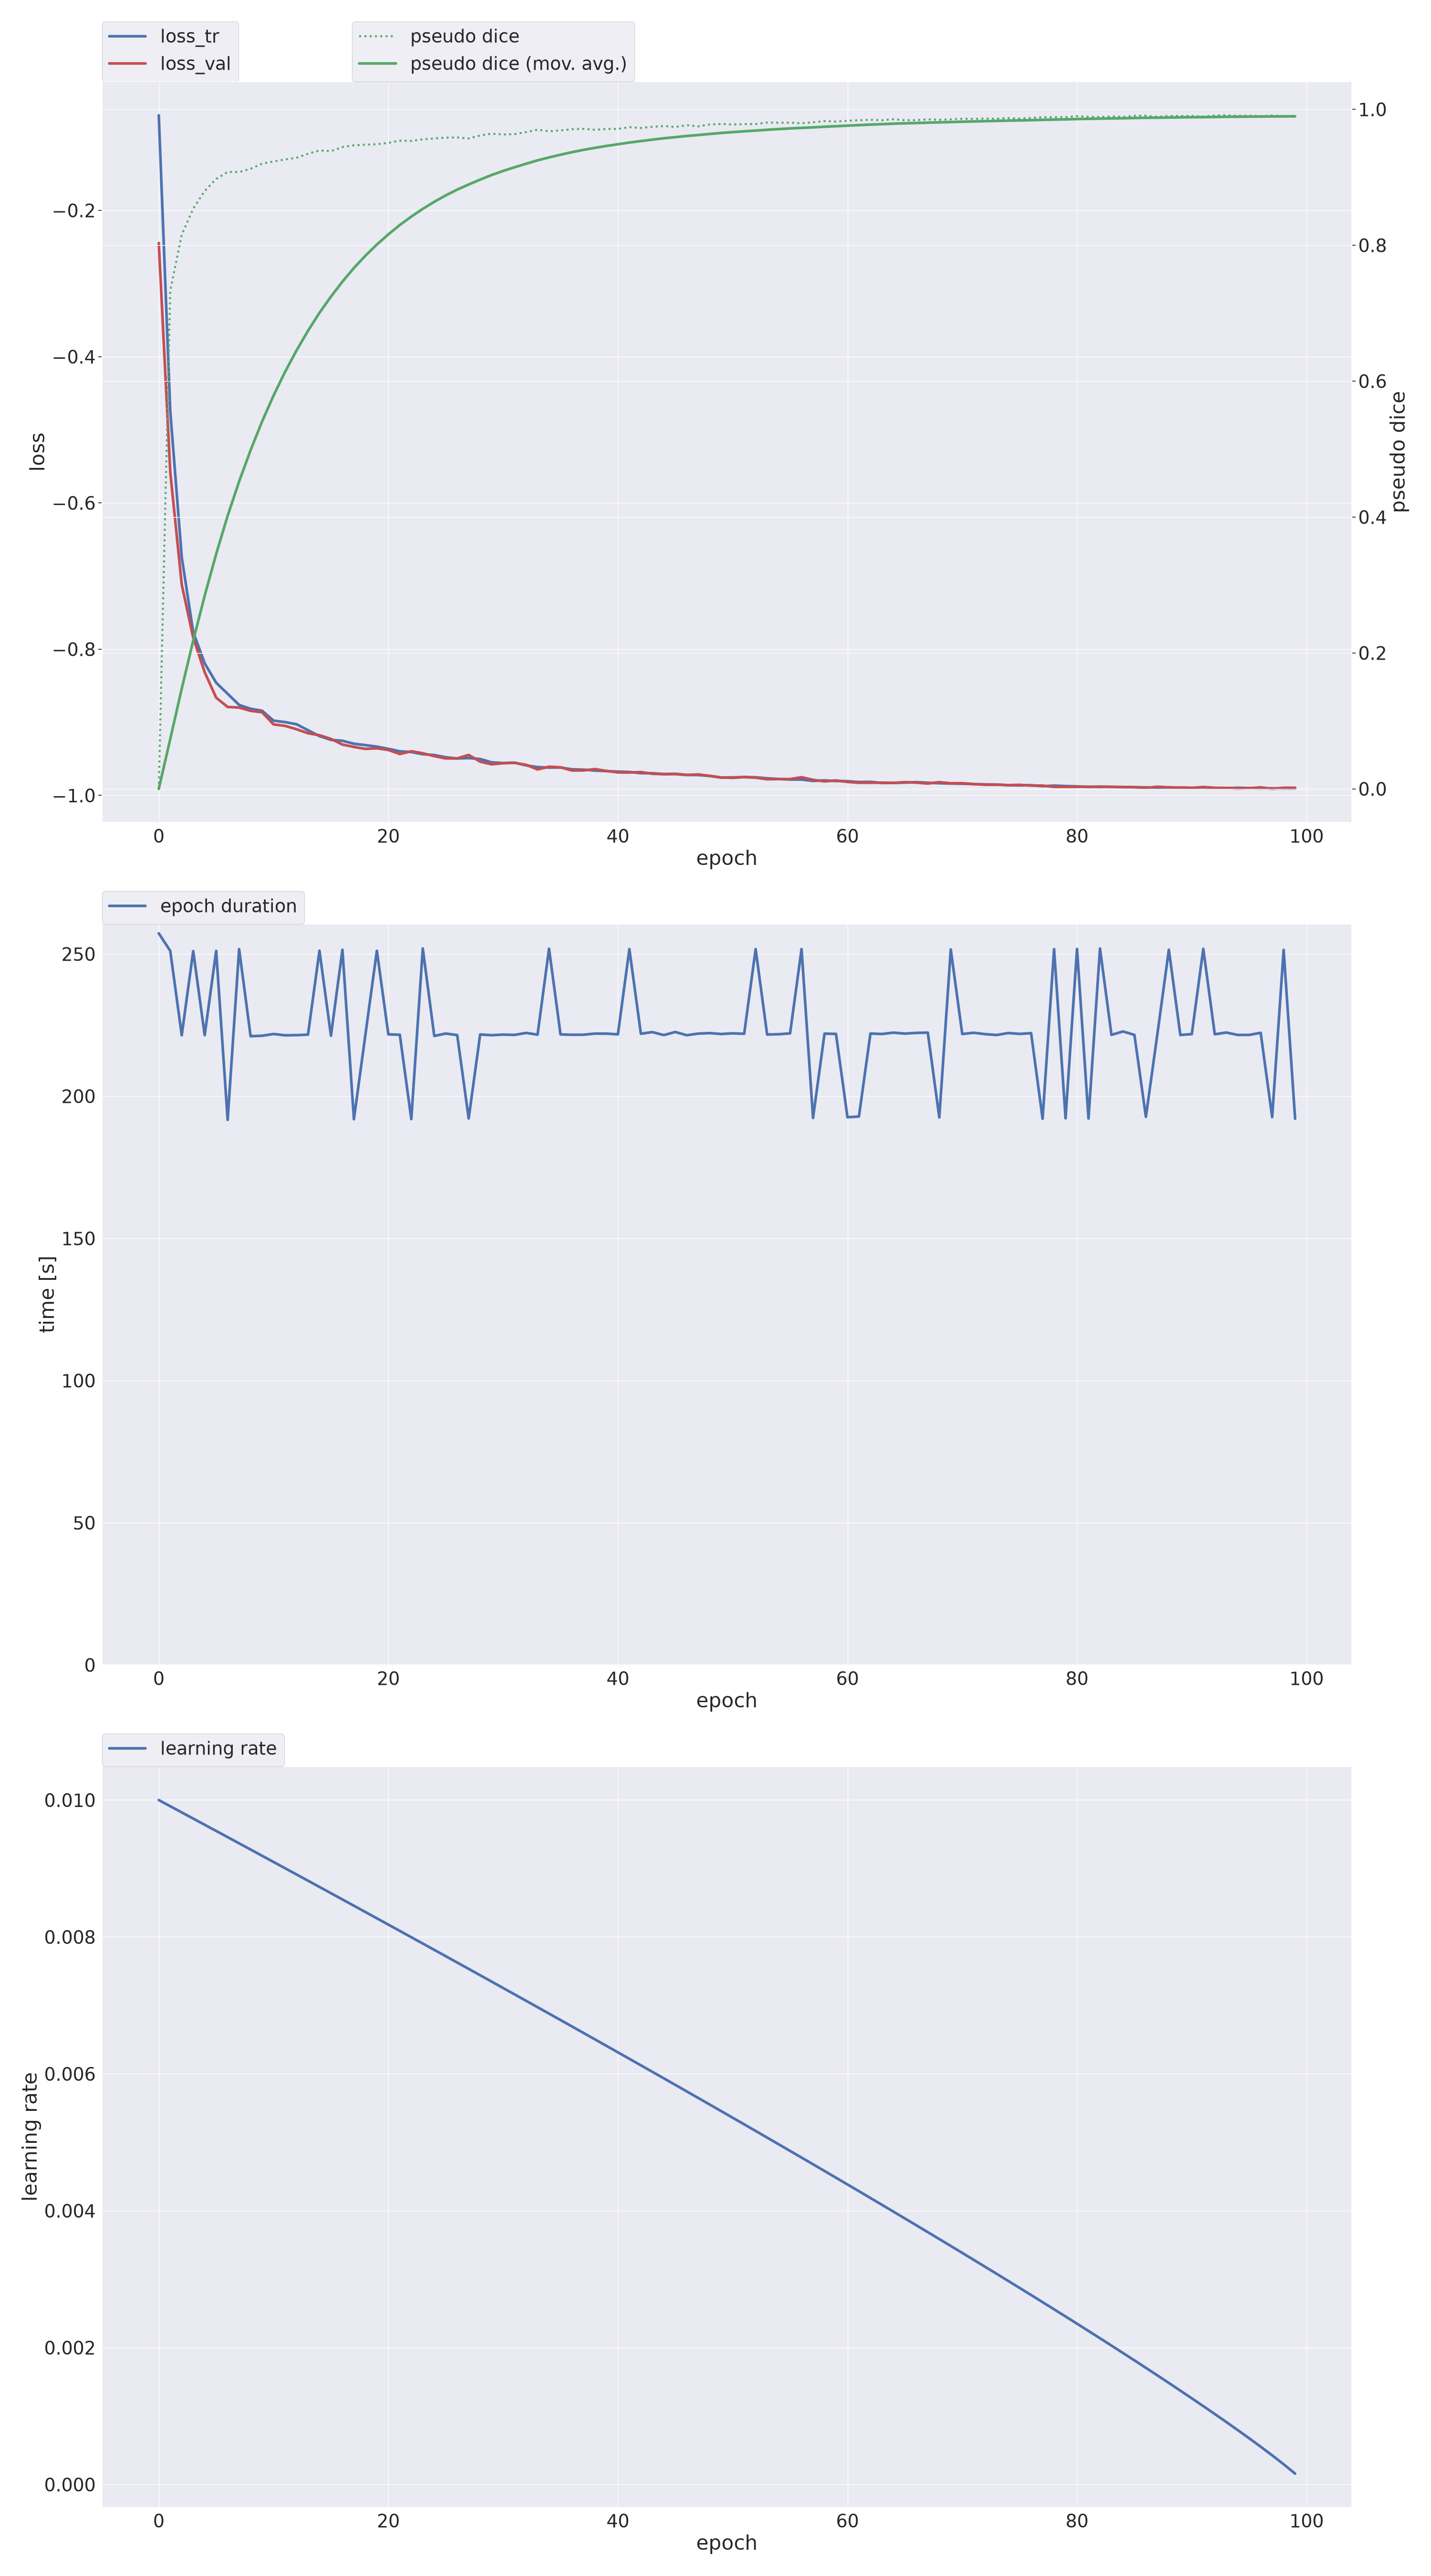

[2026-11-07 20:25:16] [overfit10] ПАУЗА: {'перегрев'}
[2026-11-07 20:25:46] [overfit10] продолжено
[2026-11-07 20:27:16] [overfit10] ПАУЗА: {'перегрев'}
[2026-11-07 20:27:46] [overfit10] продолжено
[2026-11-07 20:29:38] ВСЁ ГОТОВО



In [3]:
from IPython.display import Image, display
st = json.loads((JOBS_OVF / "status.json").read_text()) if (JOBS_OVF / "status.json").exists() else {}
age = (time.time() - st.get("heartbeat_ts", 0)) / 60
if (JOBS_OVF / "ALL_DONE").exists():  print("✅ ГОТОВО — запускайте O6")
elif (JOBS_OVF / "FAILED").exists():  print("❌ ОШИБКА:\n", (JOBS_OVF / "FAILED").read_text()[-1500:])
elif age < 3:                         print("🟢 РАБОТАЕТ | этап:", st.get("stage"))
else:                                 print(f"🔴 не отвечает {age:.0f} мин — cron перезапустит")
m = st.get("models", {}).get("overfit10", {})
print("Модель:", m.get("state", "ожидание"), "| перезапусков:", m.get("restarts", 0))
if m.get("error") and m.get("state", "").startswith(("FAILED", "упало")): print(m["error"][-800:])
g = st.get("guard", {}); print("Карты:", g.get("temp_C"), "°C | пауза:", g.get("paused") or "нет")
fold = Path(os.environ["nnUNet_results"]) / NAME_OVF / f"{OVF_TRAINER}__{PLANS}__3d_fullres" / "fold_all"
logs = sorted(fold.glob("training_log_*.txt"))
if logs:
    text = "\n".join(l.read_text(errors="ignore") for l in logs)
    ep = [int(x) for x in re.findall(r"Epoch (\d+)\s*$", text, flags=re.M)]
    dc = re.findall(r"Pseudo dice \[(?:np\.float32\()?([\d.]+)", text)
    print(f"Эпоха {max(ep) + 1 if ep else 0}/100 | pseudo Dice на тех же 10 случаях: {dc[-1] if dc else '—'}")
if (fold / "progress.png").exists(): display(Image(str(fold / "progress.png"), width=600))
print(tail(JOBS_OVF / "supervisor.log", 5))

In [5]:
import SimpleITK as sitk
from scipy import ndimage
ovf_ids = (ROOT / "overfit10_cases.txt").read_text().split()

def clusters(pr, min_vox=20):
    lab, n = ndimage.label(pr)
    sizes = ndimage.sum(pr, lab, range(1, n + 1))
    return lab, [i + 1 for i, s in enumerate(sizes) if s >= min_vox]

rows = []
for cid in ovf_ids:
    gt = sitk.GetArrayFromImage(sitk.ReadImage(str(ovf / "labelsTs" / f"{cid}.nii.gz"))) > 0
    pr = sitk.GetArrayFromImage(sitk.ReadImage(str(PRED_OVF / f"{cid}.nii.gz"))) > 0
    prob = np.load(PRED_OVF / f"{cid}.npz")["probabilities"][1]
    lab, keep = clusters(pr)
    hits = sum(gt[lab == i].any() for i in keep)
    rows.append(dict(case=cid, lesion_vox=int(gt.sum()),
                     dice=round(2 * (gt & pr).sum() / (gt.sum() + pr.sum() + 1e-8), 2),
                     found=hits > 0, FN=hits == 0, FP_clusters=len(keep) - hits,
                     max_prob_in_lesion=round(float(prob[gt].max()), 2),
                     mean_prob_in_lesion=round(float(prob[gt].mean()), 2)))
ovf_res = pd.DataFrame(rows).sort_values("dice")
display(ovf_res)
print(f"\nНайдено: {ovf_res.found.sum()}/10 | средний Dice: {ovf_res.dice.mean():.2f} | "
      f"пропусков (FN): {ovf_res.FN.sum()} | ложных кластеров (FP): {ovf_res.FP_clusters.sum()}")

,case,lesion_vox,dice,found,FN,FP_clusters,max_prob_in_lesion,mean_prob_in_lesion
3,FCD_032,521,0.08,True,False,25,1.0,0.71
7,FCD_082,1423,0.11,True,False,40,1.0,0.95
8,FCD_107,1863,0.17,True,False,25,1.0,0.92
9,FCD_124,2815,0.37,True,False,19,1.0,0.83
1,FCD_003,5136,0.40,True,False,44,1.0,0.98
4,FCD_046,10268,0.51,True,False,37,1.0,0.98
6,FCD_071,1225,0.59,True,False,14,1.0,0.79
0,FCD_002,18172,0.72,True,False,29,1.0,0.98
5,FCD_052,5158,0.83,True,False,13,1.0,0.91
2,FCD_009,31867,0.91,True,False,18,1.0,0.99



Найдено: 10/10 | средний Dice: 0.47 | пропусков (FN): 0 | ложных кластеров (FP): 264


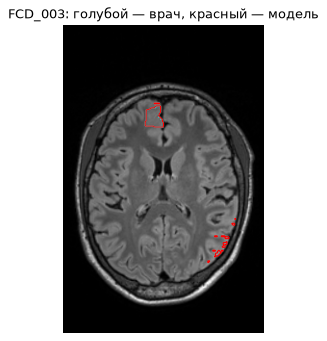

In [15]:
import nibabel as nib
import matplotlib.pyplot as plt

cid = ovf_ids[1]                       # номер случая из 10: поменяйте 0 на 1, 2, ... 9

lab  = np.asarray(nib.load(str(ovf / "labelsTs" / f"{cid}.nii.gz")).dataobj, dtype=np.uint8) > 0
z    = int(np.argwhere(lab)[:, 2].mean())                                      # срез через центр очага
fl   = np.asarray(nib.load(str(ovf / "imagesTs" / f"{cid}_0001.nii.gz")).dataobj[:, :, z])
pred = np.asarray(nib.load(str(PRED_OVF / f"{cid}.nii.gz")).dataobj[:, :, z]) > 0

plt.figure(figsize=(5, 5), dpi=80)
plt.imshow(np.rot90(fl), cmap="gray")
plt.contour(np.rot90(lab[:, :, z]), colors="cyan", linewidths=1)              # врач
if pred.any(): plt.contour(np.rot90(pred), colors="red", linewidths=1)        # модель
plt.title(f"{cid}: голубой — врач, красный — модель"); plt.axis("off"); plt.show()

In [16]:
import glob, re, os
logs = glob.glob(f"{os.environ['nnUNet_results']}/**/fold_*/training_log_*.txt", recursive=True)
for lg in logs:
    t = re.findall(r"Epoch time: ([\d.]+) s", open(lg).read())
    if t:
        m = sum(map(float, t[-20:])) / len(t[-20:])
        print(f"{m:6.0f} с/эпоху  → 250 эпох ≈ {m*250/3600:5.1f} ч   {lg.split('nnUNet_results/')[1]}")

   223 с/эпоху  → 250 эпох ≈  15.5 ч   Dataset505_FCD_overfit10/nnUNetTrainer_Overfit__nnUNetResEncUNetMPlans__3d_fullres/fold_all/training_log_2026_11_7_14_09_12.txt
   239 с/эпоху  → 250 эпох ≈  16.6 ч   Dataset501_FCD_T1FLAIR/nnUNetTrainer_FCDft__nnUNetResEncUNetMPlans__3d_fullres/fold_0/training_log_2026_11_4_17_18_41.txt
   230 с/эпоху  → 250 эпох ≈  16.0 ч   Dataset501_FCD_T1FLAIR/nnUNetTrainer_FCDft__nnUNetResEncUNetMPlans__3d_fullres/fold_0/training_log_2026_11_4_17_47_24.txt
   202 с/эпоху  → 250 эпох ≈  14.0 ч   Dataset501_FCD_T1FLAIR/nnUNetTrainer_FCD__nnUNetResEncUNetMPlans__3d_fullres/fold_0/training_log_2026_11_2_19_19_30.txt
   197 с/эпоху  → 250 эпох ≈  13.7 ч   Dataset502_FCD_T1only/nnUNetTrainer_FCD__nnUNetResEncUNetMPlans__3d_fullres/fold_0/training_log_2026_11_2_19_19_30.txt
   263 с/эпоху  → 250 эпох ≈  18.2 ч   Dataset504_FCD_BonnIDEAS/nnUNetTrainer_FCDft__nnUNetResEncUNetMPlans__3d_fullres/fold_0/training_log_2026_11_4_17_47_23.txt
